# Procgen Maze - PPO+BANS 训练结果可视化

本 notebook 用于可视化 Procgen Maze 环境中 PPO+BANS 的所有训练运行结果。


In [9]:
# ==== 基础依赖 ====
import os
from tensorboard.backend.event_processing import event_accumulator
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# 使用 seaborn style（如果可用）
try:
    plt.style.use("seaborn-v0_8")
except:
    try:
        plt.style.use("seaborn")
    except:
        pass

# ==== 自动检测项目根目录 ====
PROJECT_ROOT = os.path.dirname(os.path.abspath(""))
LOGS_DIR = os.path.join(PROJECT_ROOT, "boundary_ns_rl", "logs")

# ==== Procgen Maze PPO+BANS 的所有运行 ====
BANS_RUNS = {
    # "PPO+BANS (PPO_1)": os.path.join(LOGS_DIR, "procgen_maze_ppo_bans", "PPO_1"),
    # "PPO+BANS (PPO_3)": os.path.join(LOGS_DIR, "procgen_maze_ppo_bans", "PPO_3"),
    # "PPO+BANS (PPO_6)": os.path.join(LOGS_DIR, "procgen_maze_ppo_bans", "PPO_6"),
    "PPO+Boundary-Aware Novelty Search with beta=5.0": os.path.join(LOGS_DIR, "procgen_maze_ppo_bans", "PPO_7"),
    "PPO+Boundary-Aware Novelty Search with beta=20.0": os.path.join(LOGS_DIR, "procgen_maze_ppo_bans", "PPO_8"),
}

# 检查哪些 run 存在
existing_runs = {}
for name, path in BANS_RUNS.items():
    if os.path.isdir(path):
        existing_runs[name] = path
        print(f"  ✓ 找到: {name}")
    else:
        print(f"  ✗ 未找到: {name} at {path}")

print(f"\n找到 {len(existing_runs)} 个运行")
BANS_RUNS = existing_runs


  ✓ 找到: PPO+Boundary-Aware Novelty Search with beta=5.0
  ✓ 找到: PPO+Boundary-Aware Novelty Search with beta=20.0

找到 2 个运行


In [10]:
# ==== 辅助函数：从 TensorBoard 加载数据 ====
def load_scalar_from_event(run_dir, tag, silent=False):
    """从 TensorBoard run 目录中读取指定 tag 的 scalar 序列"""
    if not os.path.isdir(run_dir):
        if not silent:
            print(f"[WARN] Run dir not found: {run_dir}")
        return None, None
    
    ea = event_accumulator.EventAccumulator(
        run_dir,
        size_guidance={"scalars": 0}
    )
    ea.Reload()
    
    available = ea.Tags().get("scalars", [])
    if tag not in available:
        if not silent:
            print(f"[WARN] tag '{tag}' not found in {run_dir}")
        return None, None
    
    events = ea.Scalars(tag)
    steps = np.array([e.step for e in events])
    values = np.array([e.value for e in events])
    return steps, values

# ==== 加载所有 BANS 运行的数据 ====
DATA = {}

for name, run_dir in BANS_RUNS.items():
    print(f"\n加载 {name}...")
    
    # 加载各种指标
    external_steps, external_vals = load_scalar_from_event(run_dir, "rollout/episode_external_reward", silent=True)
    intrinsic_steps, intrinsic_vals = load_scalar_from_event(run_dir, "rollout/episode_intrinsic_reward", silent=True)
    total_steps, total_vals = load_scalar_from_event(run_dir, "rollout/total_reward_cumulative", silent=True)
    
    if external_vals is None or len(external_vals) == 0:
        print(f"  ✗ 无法加载 {name} 数据")
        continue
    
    # 存储数据
    DATA[name] = {
        "episode_rewards": external_vals,
        "episode_intrinsic": intrinsic_vals if intrinsic_vals is not None and len(intrinsic_vals) > 0 else np.zeros_like(external_vals),
        "episode_steps": external_steps if external_steps is not None else None,
        "total_reward_cumulative": total_vals if total_vals is not None else None,
    }
    
    print(f"  ✓ 成功加载: {len(external_vals)} 个 episodes")

print(f"\n总共加载 {len(DATA)} 个数据集: {', '.join(DATA.keys())}")



加载 PPO+Boundary-Aware Novelty Search with beta=5.0...
  ✓ 成功加载: 113 个 episodes

加载 PPO+Boundary-Aware Novelty Search with beta=20.0...
  ✓ 成功加载: 114 个 episodes

总共加载 2 个数据集: PPO+Boundary-Aware Novelty Search with beta=5.0, PPO+Boundary-Aware Novelty Search with beta=20.0



绘制对比图: PPO+Boundary-Aware Novelty Search with beta=5.0, PPO+Boundary-Aware Novelty Search with beta=20.0

绘制 Episode External Rewards...


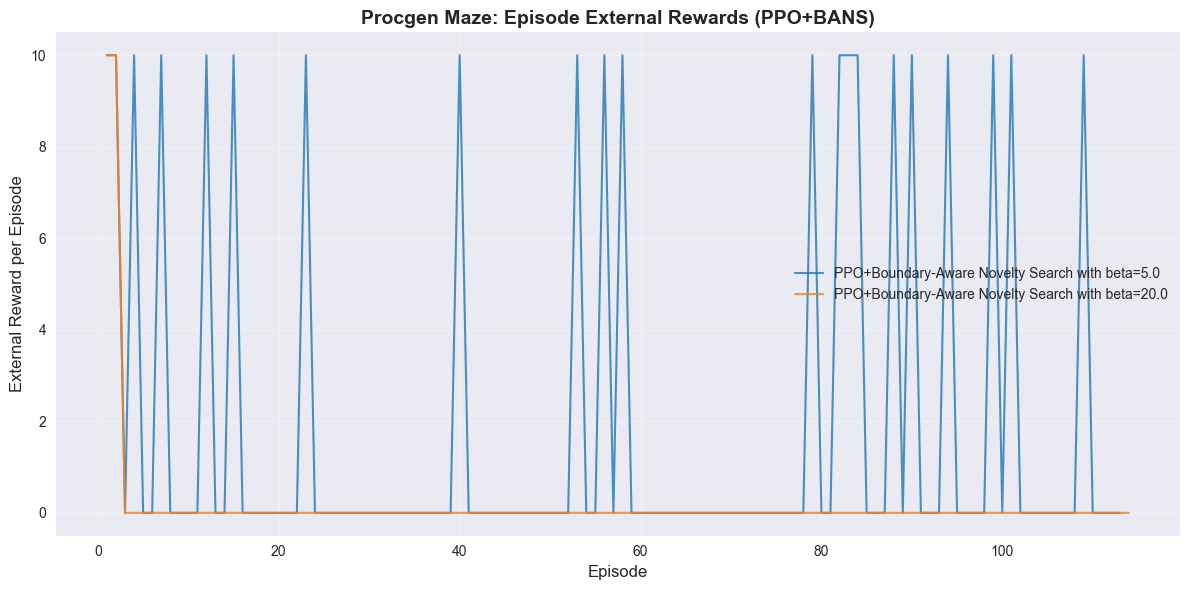


绘制 Episode Intrinsic Rewards...


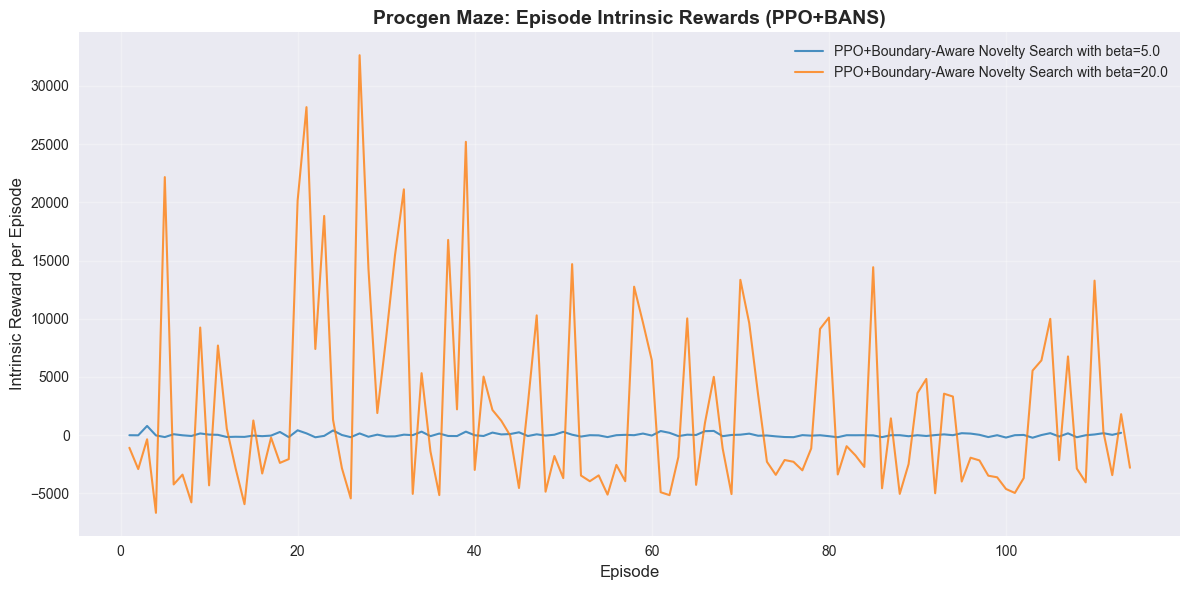


绘制 Total Reward (Cumulative)...
  [OK] PPO+Boundary-Aware Novelty Search with beta=5.0: 113 个 episodes
  [OK] PPO+Boundary-Aware Novelty Search with beta=20.0: 114 个 episodes


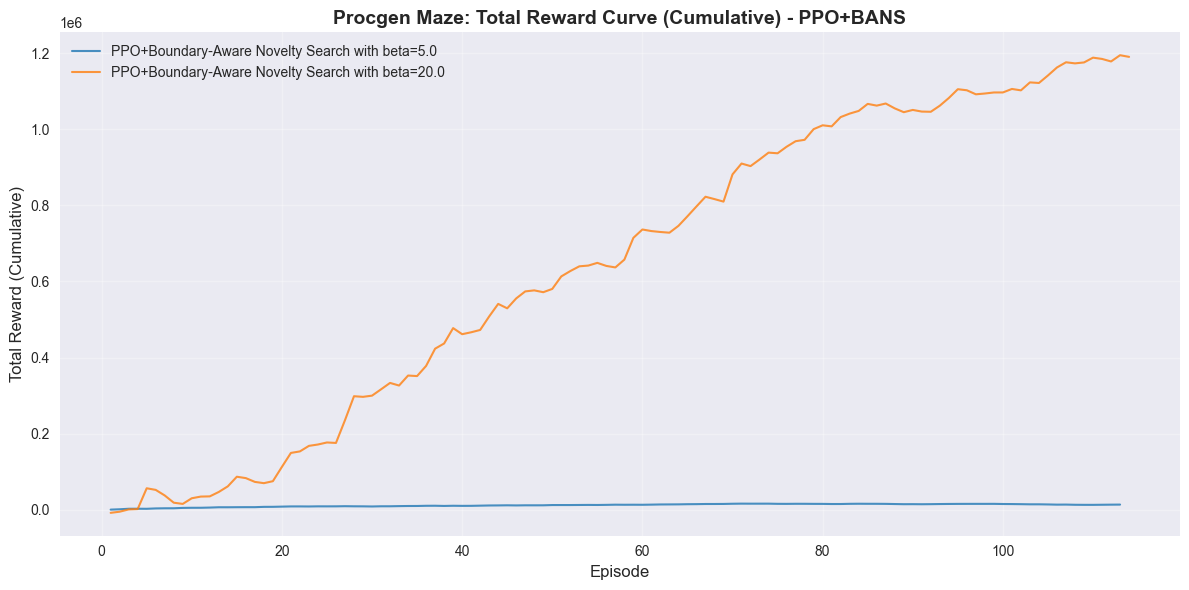

In [11]:
# ===== 绘制对比图 =====
# 固定颜色映射
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink", "tab:gray"]
color_map = {name: colors[i % len(colors)] for i, name in enumerate(DATA.keys())}

if len(DATA) > 0:
    print("\n" + "=" * 60)
    print(f"绘制对比图: {', '.join(DATA.keys())}")
    print("=" * 60)
    
    # 1. 绘制 Episode External Rewards
    print(f"\n绘制 Episode External Rewards...")
    plt.figure(figsize=(12, 6))
    for name, data in DATA.items():
        episode_rewards = data["episode_rewards"]
        x_data = np.arange(1, len(episode_rewards) + 1)
        color = color_map.get(name, None)
        plt.plot(x_data, episode_rewards, label=name, linewidth=1.5, alpha=0.8, color=color)
    plt.legend(fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("External Reward per Episode", fontsize=12)
    plt.title("Procgen Maze: Episode External Rewards (PPO+BANS)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # 2. 绘制 Episode Intrinsic Rewards
    print(f"\n绘制 Episode Intrinsic Rewards...")
    plt.figure(figsize=(12, 6))
    for name, data in DATA.items():
        episode_intrinsic = data["episode_intrinsic"]
        x_data = np.arange(1, len(episode_intrinsic) + 1)
        color = color_map.get(name, None)
        plt.plot(x_data, episode_intrinsic, label=name, linewidth=1.5, alpha=0.8, color=color)
    plt.legend(fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Intrinsic Reward per Episode", fontsize=12)
    plt.title("Procgen Maze: Episode Intrinsic Rewards (PPO+BANS)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # 3. 绘制累积总奖励曲线
    print(f"\n绘制 Total Reward (Cumulative)...")
    plt.figure(figsize=(12, 6))
    for name, data in DATA.items():
        if data["total_reward_cumulative"] is not None:
            total_reward_curve = data["total_reward_cumulative"]
            x_data = np.arange(1, len(total_reward_curve) + 1)
        else:
            # 如果没有 cumulative，从 episode rewards 计算
            episode_rewards = data["episode_rewards"]
            total_reward_curve = np.cumsum(episode_rewards)
            x_data = np.arange(1, len(total_reward_curve) + 1)
        
        color = color_map.get(name, None)
        plt.plot(x_data, total_reward_curve, label=name, linewidth=1.5, alpha=0.8, color=color)
        print(f"  [OK] {name}: {len(total_reward_curve)} 个 episodes")
    
    plt.legend(fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Total Reward (Cumulative)", fontsize=12)
    plt.title("Procgen Maze: Total Reward Curve (Cumulative) - PPO+BANS", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
else:
    print("\n未找到任何可用的数据")



为每个运行绘制详细图表...

PPO+Boundary-Aware Novelty Search with beta=5.0


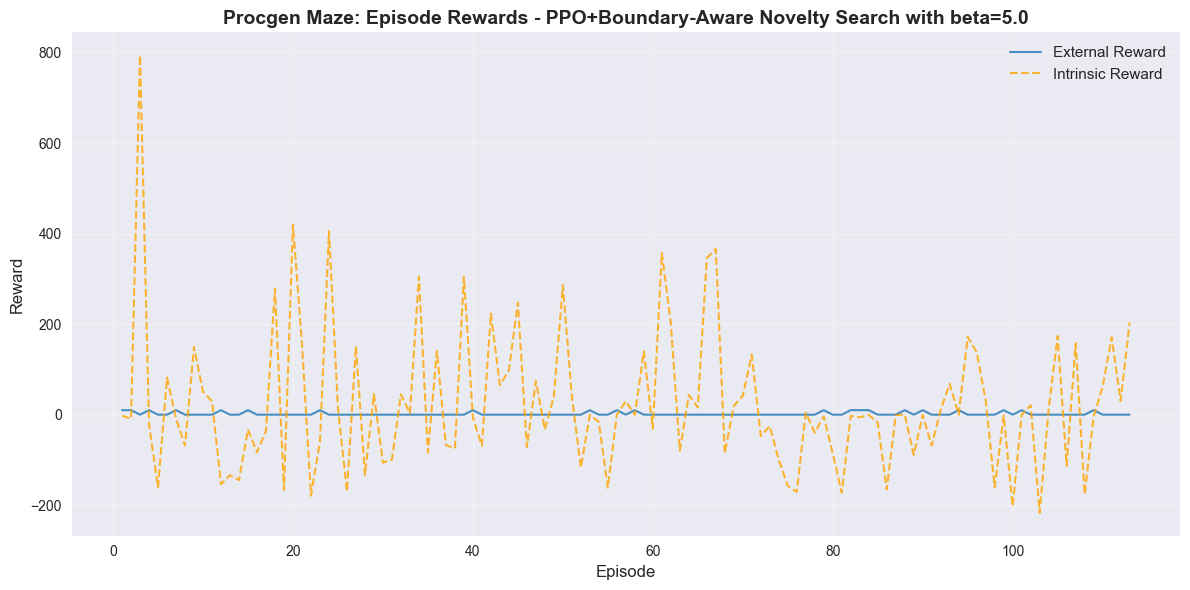

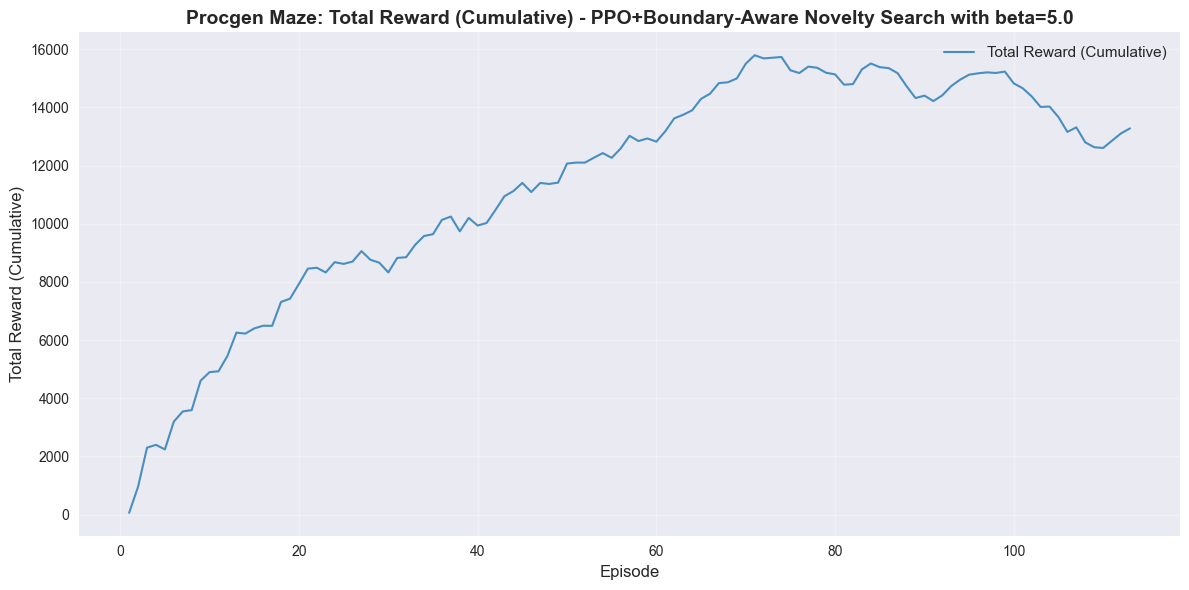


PPO+Boundary-Aware Novelty Search with beta=20.0


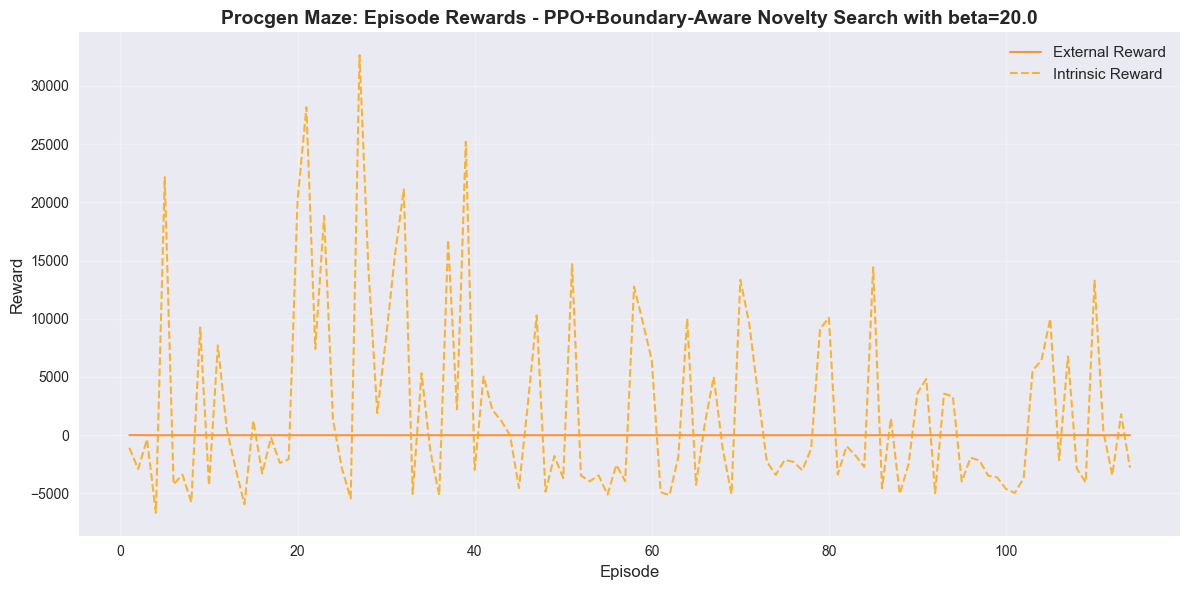

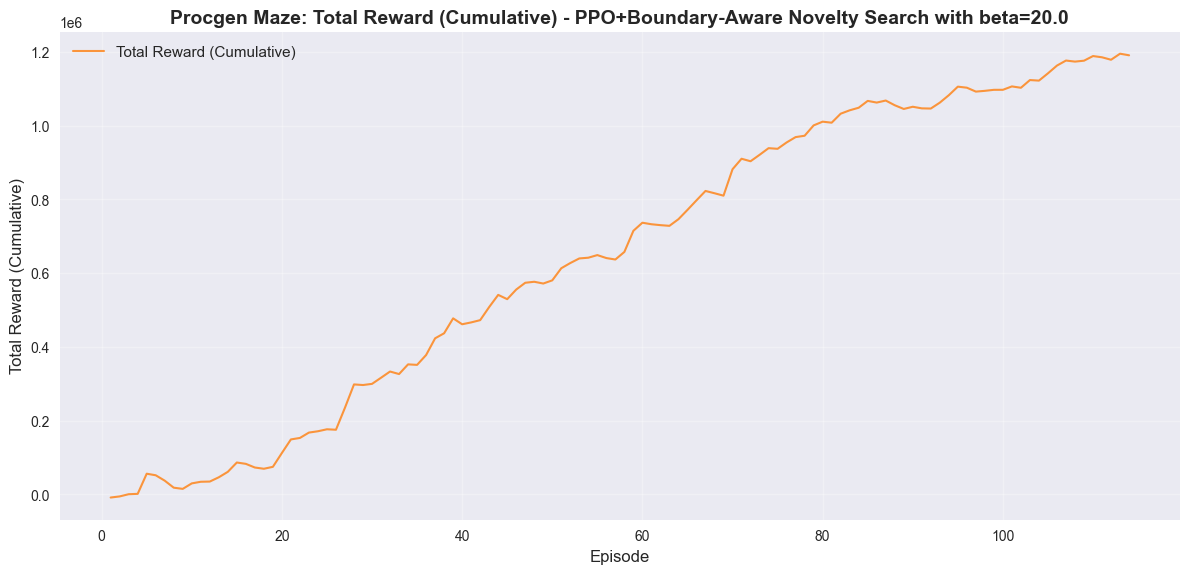

In [12]:
# ===== 为每个运行单独绘制详细图表 =====
if len(DATA) > 0:
    print("\n" + "=" * 60)
    print("为每个运行绘制详细图表...")
    print("=" * 60)
    
    for name, data in DATA.items():
        print(f"\n{'='*60}")
        print(f"{name}")
        print(f"{'='*60}")
        
        episode_rewards = data["episode_rewards"]
        episode_intrinsic = data["episode_intrinsic"]
        
        # 绘制 External + Intrinsic Rewards 对比
        plt.figure(figsize=(12, 6))
        episodes = np.arange(1, len(episode_rewards) + 1)
        color = color_map.get(name, "tab:blue")
        
        plt.plot(episodes, episode_rewards, label="External Reward", linewidth=1.5, alpha=0.8, color=color)
        
        if episode_intrinsic is not None and len(episode_intrinsic) > 0:
            if np.any(episode_intrinsic != 0):
                intrinsic_episodes = np.arange(1, len(episode_intrinsic) + 1)
                plt.plot(intrinsic_episodes, episode_intrinsic, label="Intrinsic Reward", 
                        linewidth=1.5, alpha=0.8, color="orange", linestyle='--')
        
        plt.legend(fontsize=11)
        plt.grid(True, alpha=0.3)
        plt.xlabel("Episode", fontsize=12)
        plt.ylabel("Reward", fontsize=12)
        plt.title(f"Procgen Maze: Episode Rewards - {name}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
        # 绘制累积总奖励
        if data["total_reward_cumulative"] is not None:
            total_reward_curve = data["total_reward_cumulative"]
        else:
            total_reward_curve = np.cumsum(episode_rewards)
        
        plt.figure(figsize=(12, 6))
        x_data = np.arange(1, len(total_reward_curve) + 1)
        plt.plot(x_data, total_reward_curve, label="Total Reward (Cumulative)", 
                linewidth=1.5, alpha=0.8, color=color)
        plt.legend(fontsize=11)
        plt.grid(True, alpha=0.3)
        plt.xlabel("Episode", fontsize=12)
        plt.ylabel("Total Reward (Cumulative)", fontsize=12)
        plt.title(f"Procgen Maze: Total Reward (Cumulative) - {name}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
else:
    print("\n未找到任何可用的数据")
